# BIOT 6900 · Module 7 · Knowledge Graph for Pancreatic Ductal Adenocarcinoma (PDAC)

**Author:** Deepthi Dineshkumar · Fall 2026

This notebook builds a Neo4j knowledge graph for **pancreatic ductal adenocarcinoma (PDAC)**, my Part I disease, by connecting the files I produced earlier in this course:

| Layer | Source |
|---|---|
| Genes + multi-omics evidence (RNA/protein log2FC, mutation frequency, score) | **Module 2** `targets_pdac.csv` (CPTAC-PDAC via LinkedOmicsKB) |
| Druggability (small-molecule / antibody tractability priors) | **Module 3** `targets_pdac_w3.csv` (ESM C prior) |
| Variants | **Module 5** `DPYD.tsv`, `CYP2C19.tsv`, `pgx_classified_CYP2C19.csv` (ClinVar via MyVariant.info, CADD, my provisional calls) |
| Phenotypes, pathways, drugs, related diseases | HPO, Reactome, ChEMBL/DrugBank, CPIC (curated here; every edge carries its source) |

**Design decision for the variant layer.** My Module 5 variants are pharmacogenomic (CYP2C19, pooled with DPYD), not PDAC risk variants. They therefore enter the graph through **drug metabolism**, not disease association: DPYD variants change fluorouracil exposure (fluorouracil is the backbone of FOLFIRINOX), and CYP2C19 variants change proton-pump-inhibitor exposure (PPIs are used alongside enzyme replacement for PDAC-related steatorrhea). Neither pharmacogene receives an `ASSOCIATED_WITH` edge to PDAC.

Credentials are read from a git-ignored file (`neo4j_credentials.env`), never typed into this notebook. Run with **Kernel → Restart & Run All**.

## 0 · Install and connect

In [1]:
# If the kernel restarts after installing, run the cells again from the top.
%pip install neo4j networkx matplotlib pandas requests python-dotenv

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
from dotenv import dotenv_values
from neo4j import GraphDatabase

credentials_file = Path("neo4j_credentials.env")

if not credentials_file.is_file():
    raise FileNotFoundError("Place neo4j_credentials.env beside this notebook.")

credentials = dotenv_values(credentials_file)
required = ["NEO4J_URI", "NEO4J_USERNAME", "NEO4J_PASSWORD"]

if any(not credentials.get(key) for key in required):
    raise ValueError("The credentials file is missing a required value.")

driver = GraphDatabase.driver(
    credentials["NEO4J_URI"],
    auth=(credentials["NEO4J_USERNAME"], credentials["NEO4J_PASSWORD"])
)

driver.verify_connectivity()
print("Connected to Neo4j.")

def run_query(cypher, **params):
    with driver.session() as session:
        return [record.data() for record in session.run(cypher, **params)]

Connected to Neo4j.


## 1 · My data

### 1a · Genes and their evidence (Modules 2 and 3), with identifier harmonization

Module 2 stores **Ensembl gene IDs**; Module 3 and every other source use **HGNC symbols**. Each gene is keyed on one symbol with its Ensembl ID kept as a property, so a gene arriving from several sources (CFTR appears in my Module 2 targets, in cystic fibrosis and in chronic pancreatitis) becomes **one node** whose evidence is merged rather than overwritten.

In [3]:
import os, math
import pandas as pd
import numpy as np
import networkx as nx

DISEASE = "Pancreatic ductal adenocarcinoma"
DATA = "data"

m2 = pd.read_csv(f"{DATA}/targets_pdac.csv")               # Module 2: gene column = Ensembl ID
m2["m2_rank"] = np.arange(1, len(m2) + 1)
m3 = pd.read_csv(f"{DATA}/targets_pdac_w3.csv")            # Module 3: symbol, p_sm, p_ab, final
idmap = pd.read_csv(f"{DATA}/ensembl_symbol_mapping.csv")  # Module 3 mygene mapping of my top 15

# Ensembl -> symbol. Top 15 come from my Module 3 mygene mapping; the genes added below were
# looked up in Ensembl/HGNC and are only used to key nodes, never to invent evidence.
ENS2SYM = dict(zip(idmap.ensembl_id, idmap.gene_symbol))
ENS2SYM.update({
    "ENSG00000133703": "KRAS",   "ENSG00000141510": "TP53",   "ENSG00000147889": "CDKN2A",
    "ENSG00000141646": "SMAD4",  "ENSG00000139618": "BRCA2",  "ENSG00000146648": "EGFR",
    "ENSG00000176890": "TYMS",   "ENSG00000167325": "RRM1",   "ENSG00000198900": "TOP1",
    "ENSG00000143799": "PARP1",  "ENSG00000188641": "DPYD",   "ENSG00000165841": "CYP2C19",
    "ENSG00000204983": "PRSS1",  "ENSG00000164266": "SPINK1", "ENSG00000162438": "CTRC",
})
SYM2ENS = {s: e for e, s in ENS2SYM.items()}

MY_TARGETS = list(m3.sort_values("rank").gene)              # my 15 Module 2/3 targets
DRIVERS = ["KRAS", "CDKN2A", "TP53", "SMAD4", "BRCA2"]      # canonical PDAC drivers, all in my Module 2 table

m2_by_sym = m2.assign(symbol=m2.gene.map(ENS2SYM)).dropna(subset=["symbol"]).set_index("symbol")
m3_by_sym = m3.set_index("gene")

def gene_evidence(sym):
    """Pull whatever evidence my earlier modules hold for this gene. No evidence -> no property."""
    ev = {"ensembl": SYM2ENS.get(sym, "")}
    if sym in m2_by_sym.index:
        r = m2_by_sym.loc[sym]
        ev.update(rna_lfc=round(float(r.rna_lfc), 3), prot_lfc=round(float(r.prot_lfc), 3),
                  mut_freq=round(float(r.mut_freq), 4), m2_score=round(float(r.score), 4),
                  m2_rank=int(r.m2_rank), rna_p=float(r.rna_p), prot_p=float(r.prot_p))
    if sym in m3_by_sym.index:
        r = m3_by_sym.loc[sym]
        ev.update(p_sm=round(float(r.p_sm), 4), p_ab=round(float(r.p_ab), 4),
                  druggability=round(float(max(r.p_sm, r.p_ab)), 4), m3_final=round(float(r.final), 3))
    return ev

# harmonization checks on the Module 2 side
assert all(SYM2ENS[s] in set(m2.gene) for s in MY_TARGETS + DRIVERS), "a gene is missing from targets_pdac.csv"
assert len(set(SYM2ENS[s] for s in MY_TARGETS + DRIVERS)) == len(MY_TARGETS + DRIVERS), "two symbols share an Ensembl ID"
print(f"{len(MY_TARGETS)} Module 2/3 targets + {len(DRIVERS)} drivers, each mapped Ensembl <-> symbol 1:1")
print("Module 2 ranks of the drivers:",
      {s: int(m2_by_sym.loc[s, "m2_rank"]) for s in DRIVERS})
print("No CPTAC evidence in my Module 2 table (added for pharmacology only):",
      [s for s in ["EGFR", "TYMS", "RRM1", "TOP1", "PARP1", "DPYD"] if SYM2ENS[s] not in set(m2.gene)])

15 Module 2/3 targets + 5 drivers, each mapped Ensembl <-> symbol 1:1
Module 2 ranks of the drivers: {'KRAS': 69, 'CDKN2A': 32, 'TP53': 381, 'SMAD4': 530, 'BRCA2': 306}
No CPTAC evidence in my Module 2 table (added for pharmacology only): ['EGFR', 'TYMS', 'RRM1', 'TOP1', 'PARP1', 'DPYD']


### 1b · Phenotypes, pathways, drugs, pharmacogenomic variants and related diseases

Every edge carries a **`source`** and a numeric **`confidence`** (0–1):

| Confidence | Meaning |
|---|---|
| 1.0 | curated and definitive: approved drug–target mechanism, Mendelian gene–disease, CPIC level A metabolism |
| 0.8–0.9 | curated database membership or annotation (Reactome, HPO), ClinVar assertions with ≥ 2 review stars |
| 0.5–0.7 | moderate: investigational drugs, ClinVar conflicting or low-star, non-Mendelian risk genes |
| 0.2–0.4 | weak: pharmacology-only gene–disease links, adjunct therapy, my provisional computational calls |

For gene–PDAC edges from Module 2, the confidence **is** my Module 2 multi-evidence score, so the graph inherits that calibration rather than inventing a new one.

In [4]:
# --- Phenotypes (HPO) -------------------------------------------------------------
HPO = {"Jaundice": "HP:0000952", "Abdominal pain": "HP:0002027", "Weight loss": "HP:0001824",
       "Diabetes mellitus": "HP:0000819", "Steatorrhea": "HP:0002570",
       "Exocrine pancreatic insufficiency": "HP:0001738"}
PDAC_PHENOTYPES = list(HPO)

# --- Pathways (Reactome) -> member genes ------------------------------------------
GENE_IN_PATHWAY = {
    "MAPK1/MAPK3 signaling":                    ["KRAS", "EGFR"],
    "Signaling by EGFR":                        ["EGFR", "KRAS"],
    "Transcriptional Regulation by TP53":       ["TP53"],
    "Oncogene Induced Senescence":              ["CDKN2A", "TP53"],
    "Signaling by TGFB family members":         ["SMAD4"],
    "Homology Directed Repair":                 ["BRCA2", "PARP1"],
    "Metabolism of nucleotides":                ["TYMS", "RRM1", "DPYD"],
    "Phase I - Functionalization of compounds": ["CYP2C19"],
    "O-linked glycosylation of mucins":         ["MUC16", "MUC5B"],
    "Extracellular matrix organization":        ["COL11A1", "LAMC3", "FN1"],
    "Keratinization":                           ["KRT19"],
    "Digestion of dietary lipid":               ["CEL"],
    "Purine catabolism":                        ["XDH"],
    "Mitochondrial fatty acid beta-oxidation":  ["ACADL"],
    "ABC-family proteins mediated transport":   ["CFTR"],
}

# --- Drugs: (drug, target gene, status, indication) --------------------------------
DRUGS = [
    ("Gemcitabine",         "RRM1",  "approved",        "PDAC"),
    ("Fluorouracil",        "TYMS",  "approved",        "PDAC (FOLFIRINOX / NALIRIFOX)"),
    ("Capecitabine",        "TYMS",  "approved",        "PDAC (adjuvant, with gemcitabine)"),
    ("Irinotecan liposome", "TOP1",  "approved",        "PDAC (NALIRIFOX; 2nd line)"),
    ("Erlotinib",           "EGFR",  "approved",        "PDAC (with gemcitabine)"),
    ("Olaparib",            "PARP1", "approved",        "PDAC (germline BRCA-mutated, maintenance)"),
    ("Sotorasib",           "KRAS",  "investigational", "KRAS G12C; approved in NSCLC, not PDAC"),
    (("Daraxonrasib",        "KRAS",  "approved",        "PDAC (metastatic, previously treated; FDA Aug 2026)")),
    ("Allopurinol",         "XDH",   "approved",        "gout (not PDAC)"),
    ("Febuxostat",          "XDH",   "approved",        "gout (not PDAC)"),
]
# genes that reach PDAC only because a PDAC drug acts on them (no CPTAC evidence of my own)
PHARMACOLOGY_GENES = ["TYMS", "RRM1", "TOP1", "EGFR", "PARP1"]

# --- Pharmacogenomics: the Module 5 layer -----------------------------------------
METABOLIZED_BY = [   # drug, enzyme, source
    ("Fluorouracil", "DPYD",    "CPIC DPYD / fluoropyrimidine guideline"),
    ("Capecitabine", "DPYD",    "CPIC DPYD / fluoropyrimidine guideline"),
    ("Omeprazole",   "CYP2C19", "CPIC CYP2C19 / proton pump inhibitor guideline"),
    ("Pantoprazole", "CYP2C19", "CPIC CYP2C19 / proton pump inhibitor guideline"),
]
TREATS = [   # drug, phenotype, source, confidence
    ("Pancrelipase", "Exocrine pancreatic insufficiency", "approved enzyme replacement (PERT)", 1.0),
    ("Omeprazole",   "Steatorrhea", "adjunct to PERT when the response is inadequate", 0.4),
    ("Pantoprazole", "Steatorrhea", "adjunct to PERT when the response is inadequate", 0.4),
]
PREDICTS_RESPONSE = [("BRCA2", "Olaparib", "FDA label: germline BRCA-mutated metastatic PDAC", 1.0)]

# Module 5 variants -> (gene, star allele / name, CPIC function). Evidence is read from my files.
VARIANTS = {
    "rs3918290":   ("DPYD",    "DPYD*2A (c.1905+1G>A)",  "no function"),
    "rs55886062":  ("DPYD",    "DPYD*13 (c.1679T>G)",    "no function"),
    "rs67376798":  ("DPYD",    "c.2846A>T (D949V)",      "decreased function"),
    "rs75017182":  ("DPYD",    "HapB3 (c.1129-5923C>G)", "decreased function"),
    "rs4244285":   ("CYP2C19", "CYP2C19*2",              "no function"),
    "rs4986893":   ("CYP2C19", "CYP2C19*3",              "no function"),
    "rs72558186":  ("CYP2C19", "CYP2C19*7",              "no function"),
    "rs41291556":  ("CYP2C19", "CYP2C19*8 (W120R)",      "no function"),
    "rs12248560":  ("CYP2C19", "CYP2C19*17",             "increased function"),
    "rs371241592": ("CYP2C19", "VUS Q356P",              "provisional (my Module 5 call)"),
}
# where one rsID has several ClinVar records in my files, pick the canonical one
CLINVAR_RECORD = {"rs3918290": 432, "rs4244285": 16897}

# --- Related diseases that share phenotypes with PDAC ------------------------------
RELATED = [
    {"name": "Cystic fibrosis",
     "shares": ["Exocrine pancreatic insufficiency", "Steatorrhea", "Diabetes mellitus"],
     "genes": [("CFTR", "Mendelian, causal (OMIM / ClinGen)", 1.0)],
     "drugs": [("Ivacaftor", "CFTR", "approved", "cystic fibrosis"),
               ("Elexacaftor/tezacaftor/ivacaftor", "CFTR", "approved", "cystic fibrosis")]},
    {"name": "Chronic pancreatitis",
     "shares": ["Abdominal pain", "Exocrine pancreatic insufficiency", "Steatorrhea",
                "Diabetes mellitus", "Weight loss"],
     "genes": [("PRSS1",  "hereditary pancreatitis gene (OMIM)", 0.9),
               ("SPINK1", "pancreatitis risk gene (literature)", 0.8),
               ("CTRC",   "pancreatitis risk gene (literature)", 0.7),
               ("CFTR",   "pancreatitis risk gene (literature)", 0.7)],
     "drugs": []},
    {"name": "MODY8 (CEL-MODY)",
     "shares": ["Diabetes mellitus", "Exocrine pancreatic insufficiency"],
     "genes": [("CEL", "Mendelian, causal (OMIM; Torsvik et al. 2014)", 1.0)],
     "drugs": []},
]

PATIENTS = []   # no real PDAC patient data available, so the optional patient layer is skipped
print("layers defined:", len(PDAC_PHENOTYPES), "phenotypes,", len(GENE_IN_PATHWAY), "pathways,",
      len(DRUGS) + 3, "drugs,", len(VARIANTS), "variants,", len(RELATED), "related diseases")

layers defined: 6 phenotypes, 15 pathways, 13 drugs, 10 variants, 3 related diseases


### 1c · Build the node and edge collections

`add_node` **merges** repeated nodes instead of overwriting them, and `add_edge` refuses an edge whose endpoints do not exist, so a typo cannot silently create an orphan. Every edge is given a source and a confidence.

In [5]:
NODES, EDGES = {}, []

def add_node(name, kind, **props):
    """Merge on name: a node arriving from a second source keeps the evidence it already has."""
    if name in NODES:
        assert NODES[name]["kind"] == kind, f"{name} used as two different kinds"
        for k, v in props.items():
            if v is not None and NODES[name].get(k) is None:
                NODES[name][k] = v
    else:
        NODES[name] = dict(kind=kind, **props)

def add_edge(src, rel, dst, source, confidence, **props):
    assert src in NODES and dst in NODES, f"dangling edge {src} -{rel}-> {dst}"
    EDGES.append(dict(src=src, rel=rel, dst=dst, source=source,
                      confidence=round(float(confidence), 4), **props))

add_node(DISEASE, "disease")

# --- genes -> PDAC (confidence = my Module 2 multi-evidence score) -----------------
for sym in MY_TARGETS:
    ev = gene_evidence(sym)
    add_node(sym, "gene", role="Module 2/3 target", **ev)
    add_edge(sym, "ASSOCIATED_WITH", DISEASE, "CPTAC-PDAC multi-omics (Module 2)",
             ev["m2_score"], rna_p=ev["rna_p"], prot_p=ev["prot_p"])
for sym in DRIVERS:
    ev = gene_evidence(sym)
    add_node(sym, "gene", role="PDAC driver", **ev)
    add_edge(sym, "ASSOCIATED_WITH", DISEASE,
             "CPTAC-PDAC somatic mutation + multi-omics (Module 2)", ev["m2_score"],
             mut_freq=ev["mut_freq"])
for sym in PHARMACOLOGY_GENES:
    add_node(sym, "gene", role="target of PDAC therapy", ensembl=SYM2ENS[sym])
    add_edge(sym, "ASSOCIATED_WITH", DISEASE,
             "pharmacology only (target of an approved PDAC drug, no CPTAC evidence)", 0.3)

# --- phenotypes --------------------------------------------------------------------
for ph in PDAC_PHENOTYPES:
    add_node(ph, "phenotype", hpo=HPO[ph])
    add_edge(DISEASE, "HAS_PHENOTYPE", ph, "HPO / clinical presentation", 0.8)

# --- pharmacogenes: nodes only, deliberately NOT associated with PDAC --------------
add_node("DPYD", "gene", role="pharmacogene (Module 5)", ensembl=SYM2ENS["DPYD"])
add_node("CYP2C19", "gene", role="pharmacogene (Module 5)", **gene_evidence("CYP2C19"))

# --- pathways ----------------------------------------------------------------------
for pw, genes in GENE_IN_PATHWAY.items():
    add_node(pw, "pathway")
    for g in genes:
        add_edge(g, "PARTICIPATES_IN", pw, "Reactome", 0.9)

# --- drugs -------------------------------------------------------------------------
STATUS_CONF = {"approved": 1.0, "investigational": 0.5}
for name, tgt, status, ind in DRUGS:
    add_node(name, "drug", status=status, indication=ind)
    add_edge(name, "TARGETS", tgt, "ChEMBL / DrugBank mechanism of action", STATUS_CONF[status])
for d in ["Omeprazole", "Pantoprazole", "Pancrelipase"]:
    add_node(d, "drug", status="approved", indication="supportive care in PDAC")
for drug, enz, src in METABOLIZED_BY:
    add_edge(drug, "METABOLIZED_BY", enz, src, 1.0)
for drug, ph, src, conf in TREATS:
    add_edge(drug, "TREATS", ph, src, conf)
for g, drug, src, conf in PREDICTS_RESPONSE:
    add_edge(g, "PREDICTS_RESPONSE_TO", drug, src, conf)

# --- variants, with the evidence straight out of my Module 5 files -----------------
m5 = pd.concat([pd.read_csv(f"{DATA}/DPYD.tsv", sep="\t"),
                pd.read_csv(f"{DATA}/CYP2C19.tsv", sep="\t")])
m5_vus = pd.read_csv(f"{DATA}/pgx_classified_CYP2C19.csv").set_index("rsid")

def nz(x):
    return None if pd.isna(x) else x

for rsid, (gene, allele, func) in VARIANTS.items():
    rows = m5[m5.rsid == rsid]
    if rsid in CLINVAR_RECORD:
        rows = rows[rows.clinvar_id == CLINVAR_RECORD[rsid]]
    assert len(rows) >= 1, f"{rsid} not found in my Module 5 files"
    r = rows.iloc[0]
    sig, stars = str(r.clinvar_sig), int(r.clinvar_stars)
    if rsid in m5_vus.index:                       # my own provisional call: weakest evidence
        conf = 0.3
        src = f"Module 5 provisional call: {m5_vus.loc[rsid, 'provisional_call']} (pooled, DPYD-dominated CADD calibration)"
    elif "onflicting" in sig:
        conf, src = 0.5, "ClinVar via MyVariant.info (Module 5): conflicting; CPIC still assigns a function"
    else:
        conf = 0.9 if stars >= 2 else 0.7
        src = f"ClinVar via MyVariant.info (Module 5), {stars}-star: {sig}; CPIC allele function"
    add_node(rsid, "variant", allele=allele, cpic_function=func, consequence=nz(r.consequence),
             clinvar_sig=sig, clinvar_stars=stars, cadd_phred=nz(r.cadd_phred), gnomad_af=nz(r.gnomad_af))
    add_edge(rsid, "OCCURS_IN", gene, src, conf)

# --- related diseases ---------------------------------------------------------------
for rd in RELATED:
    add_node(rd["name"], "disease")
    for ph in rd["shares"]:
        add_node(ph, "phenotype", hpo=HPO.get(ph))
        add_edge(rd["name"], "HAS_PHENOTYPE", ph, "HPO annotation", 0.8)
    for sym, src, conf in rd["genes"]:
        add_node(sym, "gene", role=f"{rd['name']} gene", **gene_evidence(sym))
        add_edge(sym, "ASSOCIATED_WITH", rd["name"], src, conf)
    for name, tgt, status, ind in rd["drugs"]:
        add_node(name, "drug", status=status, indication=ind)
        add_edge(name, "TARGETS", tgt, "ChEMBL / DrugBank mechanism of action", STATUS_CONF[status])

for pid, age, geno, prs, status in PATIENTS:
    add_node(pid, "patient", age=age, genotype=geno, prs_percentile=prs, status=status)

# ---------------- harmonization report ----------------
genes = {n: d for n, d in NODES.items() if d["kind"] == "gene"}
ens = [d["ensembl"] for d in genes.values()]
assert len(ens) == len(set(ens)), "duplicate Ensembl IDs: a gene has been split into two nodes"
assert all(e.startswith("ENSG") for e in ens), "a gene node is missing its Ensembl ID"
assert all("source" in e and "confidence" in e for e in EDGES), "an edge is missing its evidence"
multi = {g: sorted({e["dst"] for e in EDGES if e["src"] == g and e["rel"] == "ASSOCIATED_WITH"})
         for g in genes}
print("Identifier harmonization:", len(genes), "gene nodes, each with exactly one Ensembl ID")
print("Genes shared between diseases (merged into one node, not duplicated):")
for g, ds in multi.items():
    if len(ds) > 1:
        print("   ", g, "->", ds)
print()
print("nodes by kind:", pd.Series([d["kind"] for d in NODES.values()]).value_counts().to_dict())
print("edges by type:", pd.Series([e["rel"] for e in EDGES]).value_counts().to_dict())
print("TOTAL nodes:", len(NODES), " edges:", len(EDGES))

Identifier harmonization: 30 gene nodes, each with exactly one Ensembl ID
Genes shared between diseases (merged into one node, not duplicated):
    CEL -> ['MODY8 (CEL-MODY)', 'Pancreatic ductal adenocarcinoma']
    CFTR -> ['Chronic pancreatitis', 'Cystic fibrosis', 'Pancreatic ductal adenocarcinoma']

nodes by kind: {'gene': 30, 'pathway': 15, 'drug': 15, 'variant': 10, 'phenotype': 6, 'disease': 4}
edges by type: {'ASSOCIATED_WITH': 31, 'PARTICIPATES_IN': 24, 'HAS_PHENOTYPE': 16, 'TARGETS': 12, 'OCCURS_IN': 10, 'METABOLIZED_BY': 4, 'TREATS': 3, 'PREDICTS_RESPONSE_TO': 1}
TOTAL nodes: 80  edges: 101


## 2 · Load into Neo4j

Batched `UNWIND` + `MERGE`, as provided in the starter. `RESET = True` clears the database first so that **Restart & Run All** always reproduces exactly this graph, with nothing left over from an earlier run. NaNs are sent as nulls rather than as `NaN`, and the loaded counts are checked against the Python build.

In [6]:
RESET = True
if RESET:
    run_query("MATCH (n) DETACH DELETE n")

run_query("CREATE CONSTRAINT entity_name IF NOT EXISTS FOR (n:Entity) REQUIRE n.name IS UNIQUE")

def clean(v):
    if isinstance(v, np.integer):  return int(v)
    if isinstance(v, np.bool_):    return bool(v)
    if isinstance(v, (np.floating, float)):
        return None if math.isnan(float(v)) else float(v)
    return v

KIND_LABEL = {"gene": "Gene", "disease": "Disease", "phenotype": "Phenotype",
              "pathway": "Pathway", "drug": "Drug", "variant": "Variant", "patient": "Patient"}

for kind, label in KIND_LABEL.items():
    rows = [{"name": n, **{k: clean(v) for k, v in d.items()
                           if k != "kind" and clean(v) is not None}}
            for n, d in NODES.items() if d["kind"] == kind]
    if rows:
        run_query(f"UNWIND $rows AS row MERGE (e:{label}:Entity {{name: row.name}}) SET e += row",
                  rows=rows)

from collections import defaultdict
by_rel = defaultdict(list)
for e in EDGES:
    by_rel[e["rel"]].append({"src": e["src"], "dst": e["dst"],
                             "props": {k: clean(v) for k, v in e.items()
                                       if k not in ("src", "dst", "rel") and clean(v) is not None}})
for rel, rows in by_rel.items():
    run_query(f"""UNWIND $rows AS row
                  MATCH (a:Entity {{name: row.src}})
                  MATCH (b:Entity {{name: row.dst}})
                  MERGE (a)-[r:{rel}]->(b)
                  SET r += row.props""", rows=rows)

node_counts = run_query("""
    MATCH (n) UNWIND labels(n) AS l
    WITH l WHERE l <> 'Entity'
    RETURN l AS label, count(*) AS n ORDER BY n DESC
""")
rel_counts = run_query("MATCH ()-[r]->() RETURN type(r) AS rel, count(*) AS n ORDER BY n DESC")
print(pd.DataFrame(node_counts).to_string(index=False)); print()
print(pd.DataFrame(rel_counts).to_string(index=False))

n_nodes = sum(r["n"] for r in node_counts); n_rels = sum(r["n"] for r in rel_counts)
print(f"\nNeo4j holds {n_nodes} nodes and {n_rels} relationships "
      f"(Python build: {len(NODES)} nodes, {len(EDGES)} edges)")
assert (n_nodes, n_rels) == (len(NODES), len(EDGES)), "Neo4j counts differ from the build"
print("relationships missing source or confidence:",
      run_query("MATCH ()-[r]->() WHERE r.source IS NULL OR r.confidence IS NULL "
                "RETURN count(r) AS n")[0]["n"])

    label  n
     Gene 30
  Pathway 15
     Drug 15
  Variant 10
Phenotype  6
  Disease  4

                 rel  n
     ASSOCIATED_WITH 31
     PARTICIPATES_IN 24
       HAS_PHENOTYPE 16
             TARGETS 12
           OCCURS_IN 10
      METABOLIZED_BY  4
              TREATS  3
PREDICTS_RESPONSE_TO  1

Neo4j holds 80 nodes and 101 relationships (Python build: 80 nodes, 101 edges)
relationships missing source or confidence: 0


## 3 · A quick look

In the Aura console (Query tab) `MATCH (n) RETURN n LIMIT 150` explores the graph interactively; §7 draws it here.

## 4 · Query it — the opening question (Cypher)

Both queries run in Neo4j and return the evidence on the edges, not just the node names.

In [7]:
# 2 hops: drugs acting on genes associated with PDAC
q2 = run_query("""
    MATCH (d:Drug)-[t:TARGETS]->(g:Gene)-[a:ASSOCIATED_WITH]->(dis:Disease {name: $disease})
    RETURN d.name AS drug, d.status AS status, d.indication AS indication, g.name AS gene,
           t.confidence AS target_conf, a.source AS gene_disease_evidence,
           a.confidence AS gene_disease_conf
    ORDER BY gene_disease_conf DESC, drug
""", disease=DISEASE)
pd.DataFrame(q2)

,drug,status,indication,gene,target_conf,gene_disease_evidence,gene_disease_conf
0,Elexacaftor/tezacaftor/ivacaftor,approved,cystic fibrosis,CFTR,1.0,CPTAC-PDAC multi-omics (Module 2),0.9781
1,Ivacaftor,approved,cystic fibrosis,CFTR,1.0,CPTAC-PDAC multi-omics (Module 2),0.9781
2,Allopurinol,approved,gout (not PDAC),XDH,1.0,CPTAC-PDAC multi-omics (Module 2),0.9515
3,Febuxostat,approved,gout (not PDAC),XDH,1.0,CPTAC-PDAC multi-omics (Module 2),0.9515
4,Daraxonrasib,approved,"PDAC (metastatic, previously treated; FDA Aug ...",KRAS,1.0,CPTAC-PDAC somatic mutation + multi-omics (Mod...,0.8113
5,Sotorasib,investigational,"KRAS G12C; approved in NSCLC, not PDAC",KRAS,0.5,CPTAC-PDAC somatic mutation + multi-omics (Mod...,0.8113
6,Capecitabine,approved,"PDAC (adjuvant, with gemcitabine)",TYMS,1.0,pharmacology only (target of an approved PDAC ...,0.3000
7,Erlotinib,approved,PDAC (with gemcitabine),EGFR,1.0,pharmacology only (target of an approved PDAC ...,0.3000
8,Fluorouracil,approved,PDAC (FOLFIRINOX / NALIRIFOX),TYMS,1.0,pharmacology only (target of an approved PDAC ...,0.3000
9,Gemcitabine,approved,PDAC,RRM1,1.0,pharmacology only (target of an approved PDAC ...,0.3000


In [8]:
# 5 hops: drugs on genes of diseases that SHARE A SYMPTOM with PDAC (the repurposing query)
q5 = run_query("""
    MATCH (d:Drug)-[:TARGETS]->(g:Gene)-[:ASSOCIATED_WITH]->(other:Disease)
          -[:HAS_PHENOTYPE]->(p:Phenotype)<-[:HAS_PHENOTYPE]-(pdac:Disease {name: $disease})
    WHERE other <> pdac
    RETURN d.name AS repurposing_candidate, d.status AS status, g.name AS gene,
           other.name AS via_disease, collect(DISTINCT p.name) AS shared_symptoms
    ORDER BY repurposing_candidate, via_disease
""", disease=DISEASE)
pd.DataFrame(q5)

,repurposing_candidate,status,gene,via_disease,shared_symptoms
0,Elexacaftor/tezacaftor/ivacaftor,approved,CFTR,Chronic pancreatitis,"[Abdominal pain, Weight loss, Diabetes mellitu..."
1,Elexacaftor/tezacaftor/ivacaftor,approved,CFTR,Cystic fibrosis,"[Diabetes mellitus, Steatorrhea, Exocrine panc..."
2,Ivacaftor,approved,CFTR,Chronic pancreatitis,"[Abdominal pain, Weight loss, Diabetes mellitu..."
3,Ivacaftor,approved,CFTR,Cystic fibrosis,"[Diabetes mellitus, Steatorrhea, Exocrine panc..."


**Full paths.** The queries above return rows; the helper below prints whole paths — every node, every relationship, and the source and confidence on each hop — so a reader can follow the reasoning and see how strong each link is.

In [9]:
PATH_RETURN = """
    RETURN [n IN nodes(p) | n.name] AS nodes,
           [i IN range(0, size(relationships(p)) - 1) |
              [type(relationships(p)[i]),
               CASE WHEN startNode(relationships(p)[i]) = nodes(p)[i] THEN 'fwd' ELSE 'rev' END,
               relationships(p)[i].source,
               toString(relationships(p)[i].confidence)]] AS rels
"""

def show_path(cypher, **params):
    rows = run_query(cypher + PATH_RETURN + " LIMIT 1", **params)
    for row in rows:
        names, rels = row["nodes"], row["rels"]
        print("   " + names[0])
        for (rtype, direction, src, conf), nxt in zip(rels, names[1:]):
            arrow = f"--[{rtype}]-->" if direction == "fwd" else f"<--[{rtype}]--"
            print(f"      {arrow} {nxt}")
            print(f"           evidence: {src}  |  confidence {conf}")
    if not rows:
        print("   (no path found)")
    print()
    return rows

print("PATH 1 - shared-symptom repurposing: an approved cystic fibrosis drug reaches PDAC\n"
      "         through a symptom the two diseases share.\n")
_ = show_path("""
    MATCH p = (:Drug {name: 'Ivacaftor'})-[:TARGETS]->(:Gene {name: 'CFTR'})
              -[:ASSOCIATED_WITH]->(:Disease {name: 'Cystic fibrosis'})
              -[:HAS_PHENOTYPE]->(:Phenotype {name: 'Exocrine pancreatic insufficiency'})
              <-[:HAS_PHENOTYPE]-(:Disease {name: $disease})
""", disease=DISEASE)

print("PATH 2 - pharmacogenomics (Module 5): a DPYD variant to the first-line PDAC drug\n"
      "         whose clearance it controls.\n")
_ = show_path("""
    MATCH p = (:Variant {name: 'rs3918290'})-[:OCCURS_IN]->(:Gene {name: 'DPYD'})
              <-[:METABOLIZED_BY]-(:Drug {name: 'Fluorouracil'})-[:TARGETS]->(:Gene {name: 'TYMS'})
              -[:ASSOCIATED_WITH]->(:Disease {name: $disease})
""", disease=DISEASE)

print("PATH 3 - pharmacogenomics at the symptom level: my Module 5 gene to a PDAC symptom.\n")
_ = show_path("""
    MATCH p = (:Variant {name: 'rs4244285'})-[:OCCURS_IN]->(:Gene {name: 'CYP2C19'})
              <-[:METABOLIZED_BY]-(:Drug {name: 'Omeprazole'})-[:TREATS]->(:Phenotype {name: 'Steatorrhea'})
              <-[:HAS_PHENOTYPE]-(:Disease {name: $disease})
""", disease=DISEASE)

PATH 1 - shared-symptom repurposing: an approved cystic fibrosis drug reaches PDAC
         through a symptom the two diseases share.

   Ivacaftor
      --[TARGETS]--> CFTR
           evidence: ChEMBL / DrugBank mechanism of action  |  confidence 1.0
      --[ASSOCIATED_WITH]--> Cystic fibrosis
           evidence: Mendelian, causal (OMIM / ClinGen)  |  confidence 1.0
      --[HAS_PHENOTYPE]--> Exocrine pancreatic insufficiency
           evidence: HPO annotation  |  confidence 0.8
      <--[HAS_PHENOTYPE]-- Pancreatic ductal adenocarcinoma
           evidence: HPO / clinical presentation  |  confidence 0.8

PATH 2 - pharmacogenomics (Module 5): a DPYD variant to the first-line PDAC drug
         whose clearance it controls.

   rs3918290
      --[OCCURS_IN]--> DPYD
           evidence: ClinVar via MyVariant.info (Module 5), 2-star: Pathogenic/Likely pathogenic; CPIC allele function  |  confidence 0.9
      <--[METABOLIZED_BY]-- Fluorouracil
           evidence: CPIC DPYD / fluoropyri

In [10]:
# Which Module 5 variants change exposure to a drug used in PDAC care?
pd.DataFrame(run_query("""
    MATCH (v:Variant)-[o:OCCURS_IN]->(g:Gene)<-[:METABOLIZED_BY]-(d:Drug)
    RETURN g.name AS gene, v.name AS variant, v.allele AS allele,
           v.cpic_function AS cpic_function, v.clinvar_sig AS clinvar,
           v.clinvar_stars AS stars, v.cadd_phred AS cadd, o.confidence AS edge_conf,
           collect(DISTINCT d.name) AS affects_drugs
    ORDER BY gene, edge_conf DESC, variant
"""))

,gene,variant,allele,cpic_function,clinvar,stars,cadd,edge_conf,affects_drugs
0,CYP2C19,rs12248560,CYP2C19*17,increased function,Benign; other,2,3.031,0.9,"[Omeprazole, Pantoprazole]"
1,CYP2C19,rs72558186,CYP2C19*7,no function,drug response,4,NaN,0.9,"[Omeprazole, Pantoprazole]"
2,CYP2C19,rs41291556,CYP2C19*8 (W120R),no function,other,1,25.700,0.7,"[Omeprazole, Pantoprazole]"
3,CYP2C19,rs4244285,CYP2C19*2,no function,drug response,0,5.686,0.7,"[Omeprazole, Pantoprazole]"
4,CYP2C19,rs4986893,CYP2C19*3,no function,drug response,0,35.000,0.7,"[Omeprazole, Pantoprazole]"
5,CYP2C19,rs371241592,VUS Q356P,provisional (my Module 5 call),Uncertain significance,1,23.600,0.3,"[Omeprazole, Pantoprazole]"
6,DPYD,rs3918290,DPYD*2A (c.1905+1G>A),no function,Pathogenic/Likely pathogenic,2,23.700,0.9,"[Fluorouracil, Capecitabine]"
7,DPYD,rs55886062,DPYD*13 (c.1679T>G),no function,Pathogenic,2,31.000,0.9,"[Fluorouracil, Capecitabine]"
8,DPYD,rs75017182,HapB3 (c.1129-5923C>G),decreased function,drug response,3,0.378,0.9,"[Fluorouracil, Capecitabine]"
9,DPYD,rs67376798,c.2846A>T (D949V),decreased function,Conflicting interpretations of pathogenicity,1,29.900,0.5,"[Fluorouracil, Capecitabine]"


## 5 · Biomarker prioritization (centrality fused with evidence)

PageRank runs client-side in NetworkX on the same nodes and edges that were loaded into Neo4j, then is **fused** with my own evidence into a single ranking:

```
fused = 0.4 x PageRank percentile  +  0.4 x Module 2 evidence  +  0.2 x druggability
```

* **PageRank percentile** — rank among gene nodes, so the three very different scales are comparable.
* **Module 2 evidence** — my multi-evidence score (0–1); 0 for genes with no CPTAC evidence of my own.
* **Druggability** — my Module 3 tractability prior (the larger of `p_sm`, `p_ab`); for genes outside my Module 3 top 15, 1.0 if an approved drug targets them, 0.5 if only an investigational one, else 0.

Only genes with an `ASSOCIATED_WITH` edge to PDAC are ranked as biomarker candidates. The pharmacogenes and related-disease-only genes are listed separately, because a high PageRank there reflects their position in the graph, not evidence that they mark PDAC.

In [11]:
G = nx.DiGraph()
for name, d in NODES.items():
    G.add_node(name, **d)
for e in EDGES:
    G.add_edge(e["src"], e["dst"], **{k: v for k, v in e.items() if k not in ("src", "dst")})

pr = nx.pagerank(G)
gene_nodes = [n for n, d in G.nodes(data=True) if d["kind"] == "gene"]

def drug_status_score(g):
    st = [NODES[e["src"]]["status"] for e in EDGES if e["rel"] == "TARGETS" and e["dst"] == g]
    return 1.0 if "approved" in st else (0.5 if st else 0.0)

rows = []
for g in gene_nodes:
    d = NODES[g]
    pdac = any(e["src"] == g and e["dst"] == DISEASE and e["rel"] == "ASSOCIATED_WITH" for e in EDGES)
    prior = d.get("druggability")
    rows.append({"gene": g, "role": d.get("role"), "pdac_associated": pdac,
                 "pagerank": round(pr[g], 4), "degree": G.degree(g),
                 "m2_score": d.get("m2_score"), "m2_rank": d.get("m2_rank"),
                 "druggability": prior if prior is not None else drug_status_score(g),
                 "drug_evidence": "Module 3 prior" if prior is not None else "drug status",
                 "n_drugs": sum(1 for e in EDGES if e["rel"] == "TARGETS" and e["dst"] == g)})

tab = pd.DataFrame(rows)
tab["pagerank_pct"] = tab["pagerank"].rank(pct=True).round(3)
tab["evidence"] = tab["m2_score"].fillna(0.0)
tab["fused"] = (0.4 * tab.pagerank_pct + 0.4 * tab.evidence + 0.2 * tab.druggability).round(3)

cols = ["gene", "role", "fused", "pagerank", "pagerank_pct", "m2_score", "m2_rank",
        "druggability", "drug_evidence", "n_drugs", "degree"]
biomarkers = tab[tab.pdac_associated].sort_values("fused", ascending=False).reset_index(drop=True)
biomarkers.index += 1
print(f"Candidate biomarkers for {DISEASE} (PageRank fused with my Module 2/3 evidence):\n")
print(biomarkers[cols].to_string())

print("\nIn the graph but NOT ranked as PDAC biomarkers (no association edge to PDAC):")
print(tab[~tab.pdac_associated][["gene", "role", "pagerank", "degree"]]
      .sort_values("pagerank", ascending=False).to_string(index=False))

biomarkers[cols].to_csv("biomarker_ranking.csv", index_label="rank")

print("\nSensitivity of the top 5 to the fusion weights (PageRank / evidence / druggability):")
for w in [(0.4, 0.4, 0.2), (0.6, 0.3, 0.1), (0.2, 0.6, 0.2), (0.33, 0.33, 0.34)]:
    f = w[0] * tab.pagerank_pct + w[1] * tab.evidence + w[2] * tab.druggability
    top = tab.assign(f=f).loc[tab.pdac_associated].nlargest(5, "f").gene.tolist()
    print(f"   {w}: {top}")

Candidate biomarkers for Pancreatic ductal adenocarcinoma (PageRank fused with my Module 2/3 evidence):

       gene                    role  fused  pagerank  pagerank_pct  m2_score  m2_rank  druggability   drug_evidence  n_drugs  degree
1      KRAS             PDAC driver  0.885    0.0164         0.900    0.8113     69.0        1.0000     drug status        2       5
2       XDH       Module 2/3 target  0.841    0.0164         0.900    0.9515      9.0        0.5035  Module 3 prior        2       4
3      CFTR       Module 2/3 target  0.760    0.0164         0.900    0.9781      2.0        0.0444  Module 3 prior        2       6
4       CEL       Module 2/3 target  0.668    0.0061         0.350    0.9620      4.0        0.7163  Module 3 prior        0       3
5     MUC5B       Module 2/3 target  0.626    0.0061         0.350    0.9419     13.0        0.5458  Module 3 prior        0       2
6     NPTX2       Module 2/3 target  0.619    0.0061         0.350    0.9483     11.0        0.50

## 6 · Communities

Greedy modularity clustering (NetworkX) on the undirected graph. Each community is printed with its composition by node kind, so it can be read as a mechanism or a subtype rather than as a list of names.

In [12]:
from networkx.algorithms.community import greedy_modularity_communities, modularity

U = G.to_undirected()
comms = greedy_modularity_communities(U)
comm_of = {n: i for i, c in enumerate(comms) for n in c}

print(f"{len(comms)} communities, modularity = {modularity(U, comms):.3f}\n")
for i, c in enumerate(comms):
    kinds = pd.Series([NODES[n]["kind"] for n in c]).value_counts().to_dict()
    members = {k: sorted(n for n in c if NODES[n]["kind"] == k) for k in kinds}
    print(f"Community {i}  ({len(c)} nodes: {kinds})")
    for k in ["disease", "gene", "drug", "variant", "pathway", "phenotype"]:
        if k in members:
            print(f"   {k:10s}: {', '.join(members[k])}")
    print()

8 communities, modularity = 0.626

Community 0  (22 nodes: {'gene': 14, 'pathway': 5, 'phenotype': 1, 'drug': 1, 'disease': 1})
   disease   : Pancreatic ductal adenocarcinoma
   gene      : ACADL, BRSK2, COL11A1, EPS8L3, FN1, KRT19, LAMC3, LRP1B, MUC16, MUC5B, NOS1, NPTX2, SMAD4, TOP1
   drug      : Irinotecan liposome
   pathway   : Extracellular matrix organization, Keratinization, Mitochondrial fatty acid beta-oxidation, O-linked glycosylation of mucins, Signaling by TGFB family members
   phenotype : Jaundice

Community 1  (17 nodes: {'gene': 5, 'phenotype': 4, 'disease': 3, 'drug': 3, 'pathway': 2})
   disease   : Chronic pancreatitis, Cystic fibrosis, MODY8 (CEL-MODY)
   gene      : CEL, CFTR, CTRC, PRSS1, SPINK1
   drug      : Elexacaftor/tezacaftor/ivacaftor, Ivacaftor, Pancrelipase
   pathway   : ABC-family proteins mediated transport, Digestion of dietary lipid
   phenotype : Abdominal pain, Diabetes mellitus, Exocrine pancreatic insufficiency, Weight loss

Community 2  (11 

## 7 · Visualize and export

The graph coloured by node kind with a legend, saved as `my_knowledge_graph.png`, plus the node and edge tables as `nodes.csv` and `edges.csv`. All three are graded artifacts and are committed to the repo.

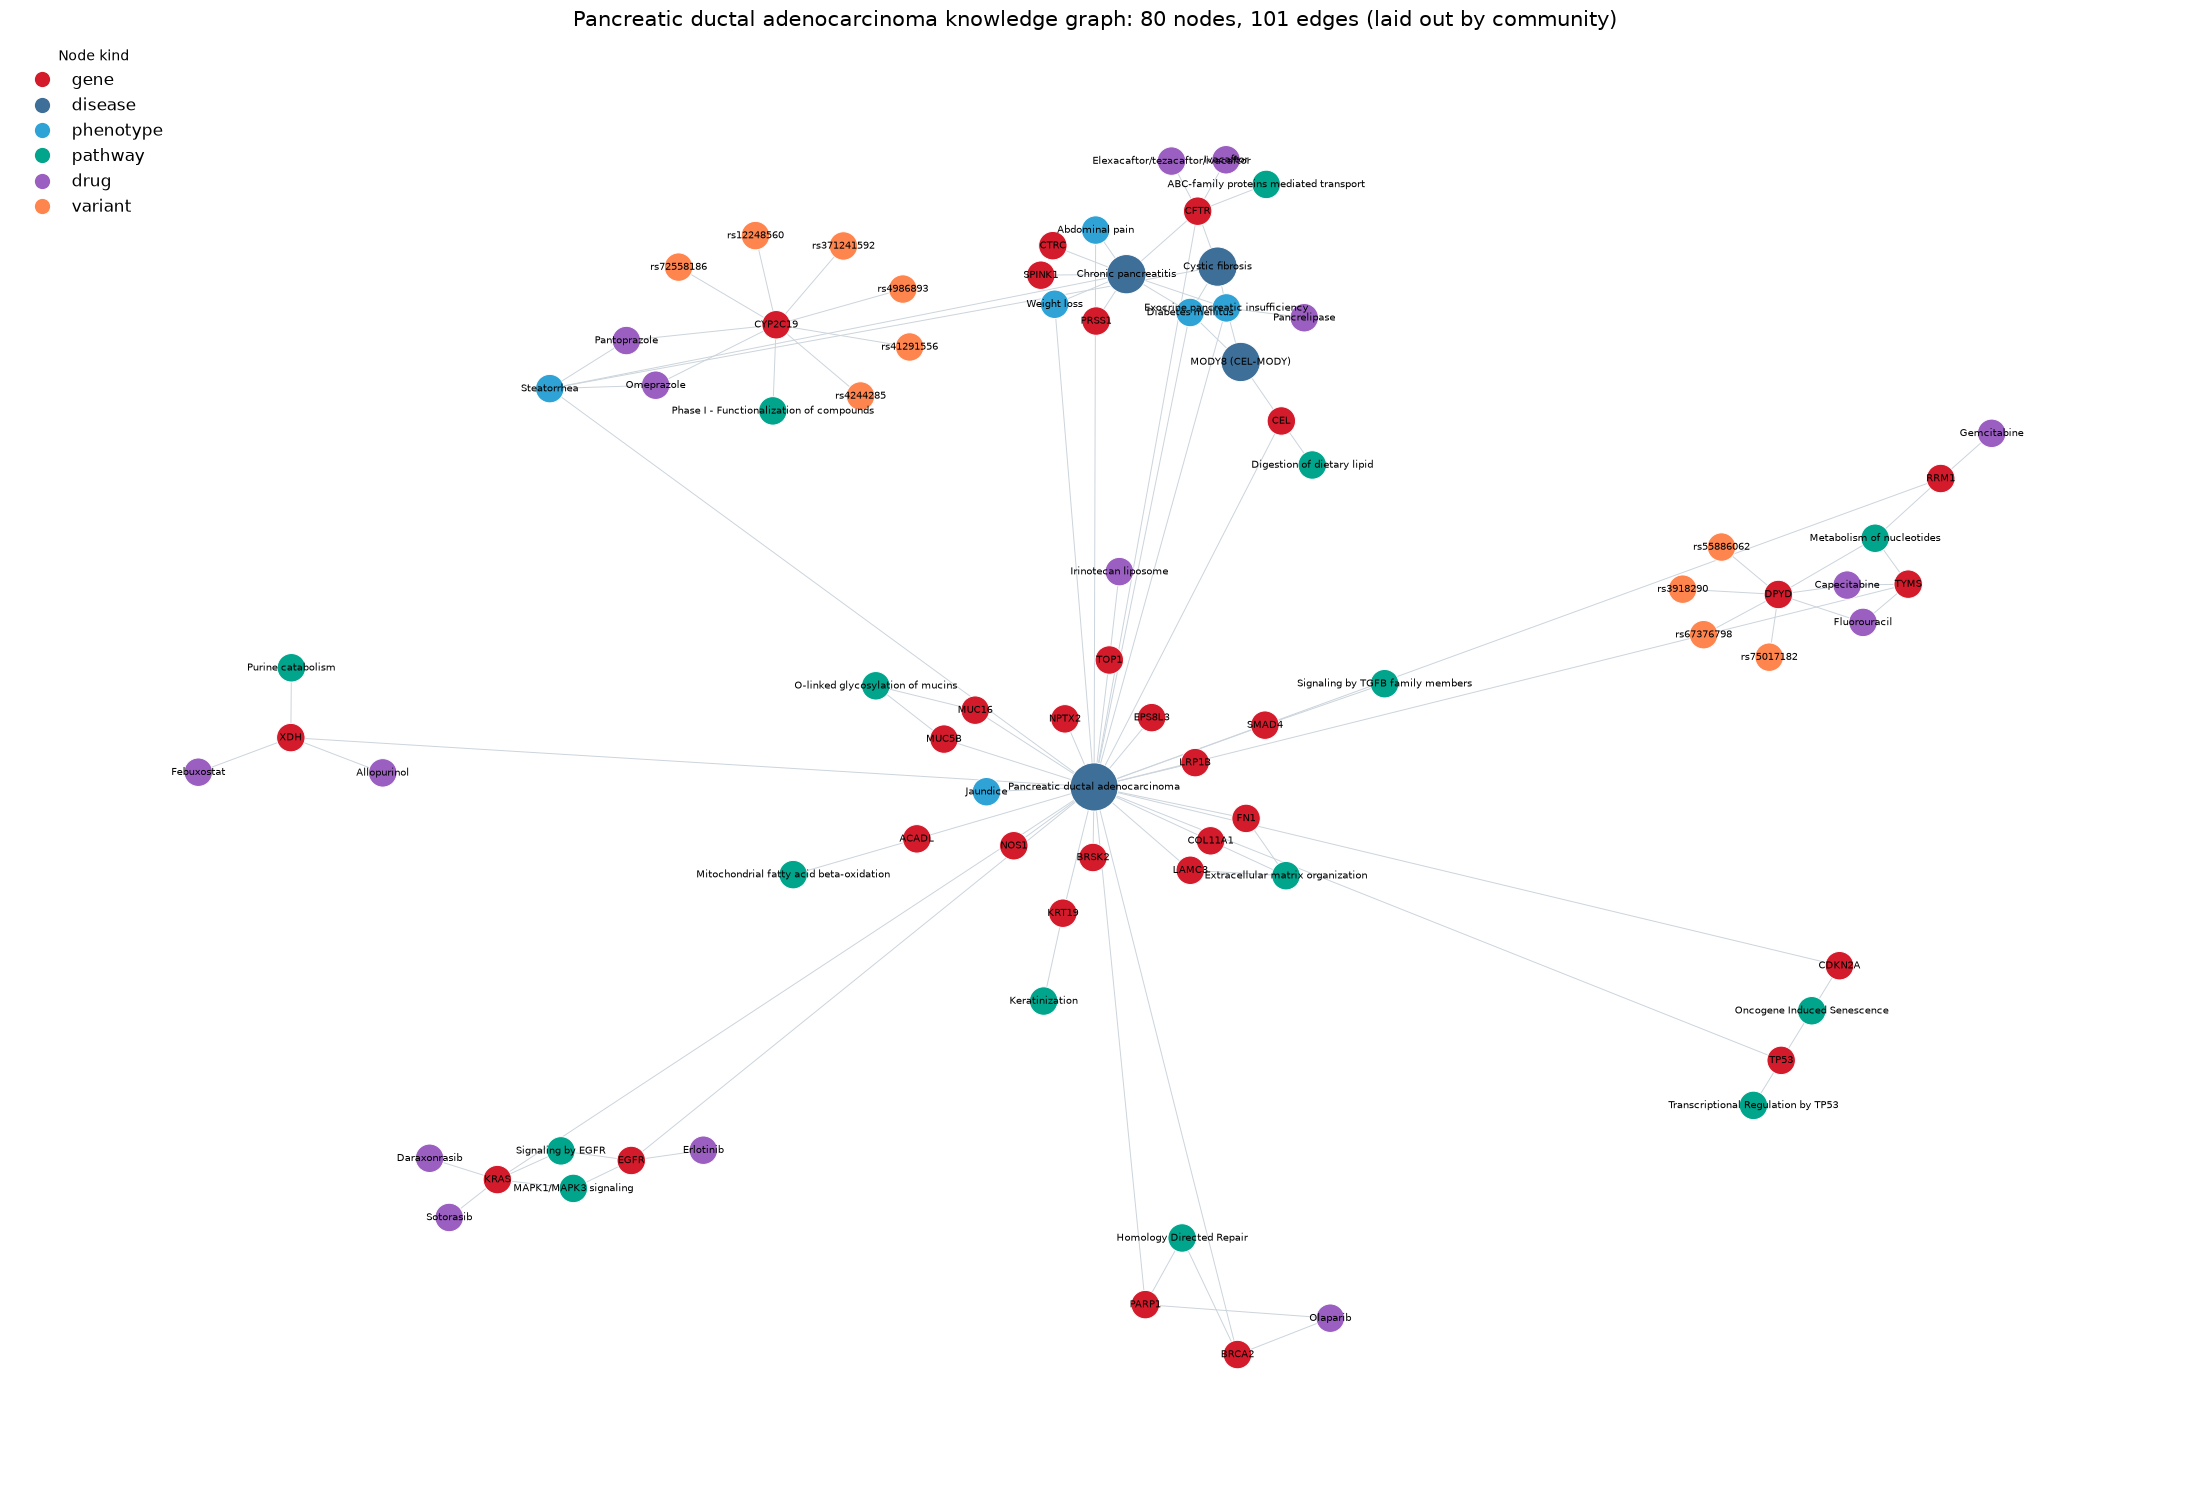

saved my_knowledge_graph.png, nodes.csv, edges.csv, biomarker_ranking.csv


In [13]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

KIND_COLOR = {"gene": "#D41B2C", "disease": "#3E6F99", "phenotype": "#2FA3D6",
              "pathway": "#00A58C", "drug": "#9A5FC0", "variant": "#FF854F", "patient": "#8A94A3"}

# Community-aware layout: lay the communities out relative to each other, then lay out the
# members of each one inside its own disc. A plain spring layout piles everything onto the
# PDAC hub and the labels become unreadable.
U = G.to_undirected()
Q = nx.Graph()
Q.add_nodes_from(range(len(comms)))
for u, v in U.edges():
    if comm_of[u] != comm_of[v]:
        Q.add_edge(comm_of[u], comm_of[v])
centers = nx.spring_layout(Q, seed=3, k=4.0, iterations=600)

pos = {}
for i, c in enumerate(comms):
    inner = nx.spring_layout(U.subgraph(c), seed=5, k=1.6, iterations=400)
    radius = 0.085 * len(c) ** 0.66
    for n, xy in inner.items():
        pos[n] = np.array(centers[i]) * 1.6 + np.array(xy) * radius

sizes = [1200 if n == DISEASE else 800 if NODES[n]["kind"] == "disease" else 420 for n in G]
plt.figure(figsize=(22, 15))
nx.draw_networkx_edges(G, pos, edge_color="#CBD4DC", width=0.7, arrows=False)
nx.draw_networkx_nodes(G, pos, node_size=sizes,
                       node_color=[KIND_COLOR[NODES[n]["kind"]] for n in G],
                       edgecolors="white", linewidths=0.7)
nx.draw_networkx_labels(G, pos, font_size=7.5)
handles = [Line2D([0], [0], marker="o", color="w", markerfacecolor=c, markersize=12, label=k)
           for k, c in KIND_COLOR.items() if any(NODES[n]["kind"] == k for n in G)]
plt.legend(handles=handles, loc="upper left", frameon=False, fontsize=12, title="Node kind")
plt.axis("off")
plt.title(f"{DISEASE} knowledge graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges "
          f"(laid out by community)", fontsize=15)
plt.tight_layout()
plt.savefig("my_knowledge_graph.png", dpi=150, bbox_inches="tight")
plt.show()

pd.DataFrame([{"name": n, "community": comm_of.get(n),
               **{k: clean(v) for k, v in d.items()}} for n, d in NODES.items()]) \
  .to_csv("nodes.csv", index=False)
pd.DataFrame(EDGES).to_csv("edges.csv", index=False)
print("saved my_knowledge_graph.png, nodes.csv, edges.csv, biomarker_ranking.csv")

## 8 · Report and submission

The interpretation — schema and evidence, top targets, a path-based hypothesis, the community reading and the limitations — is in the report PDF in this folder.

**Submitted:** this notebook (run with **Kernel → Restart & Run All**), `my_knowledge_graph.png`, `nodes.csv`, `edges.csv`, `biomarker_ranking.csv`, the report PDF and the README. `neo4j_credentials.env` is git-ignored and is never committed.

To start over:

```cypher
MATCH (n) DETACH DELETE n      // wipes the database - run deliberately
```